# ETT: 4系列のTCN・負荷特徴量選択

ETTh1・ETTh2・ETTm1・ETTm2を順番に処理し、各系列についてTCNの負荷なし基準モデルと、相関分析で選んだ負荷特徴量を加えたモデルを比較する。直前OTを基準に、過去24時間から次の観測時刻のOT変化を予測する。

- ETThは1時間先、ETTmは15分先を予測する。対象時刻のOTや負荷は入力せず、直前までに観測済みの情報のみを使用する。
- 各系列を時系列順に70%学習、10%検証、20%テストに分け、標準化と月別・時刻別パターンは学習期間のみから計算する。
- 学習期間のPearson相関で負荷6列の全15ペアを調べる。|r|>0.9の冗長な特徴量は、OTとの絶対相関が高い方を優先して入力から除く。15ペアすべてをモデル学習するのではなく、選択した負荷列セット1つだけを負荷あり入力にする。
- 各系列では負荷なし・選択負荷ありの2構成だけを使い、4つの学習プリセット（base、reg、light、slow_lr）を比較する。合計32回学習する。プリセットは補正係数1.0の検証MAEで選び、選択済みモデルの検証予測に係数0.5、0.75、1.0を適用して補正係数を選ぶ。この段階では再学習しない。
- ETTmは早期停止を強め、patience=3、min_delta=1e-5を使う（ETThはpatience=5）。同じ検証期間を早期停止と設定選択に使うため、検証誤差は楽観的になり得る。
- 結果はDriveの `assignment-main/model_output_tcn_all_modified/<DATASET>` に保存する。

## Colabでの準備

コピー元の古い実行結果が表示されている場合があるため、先頭から再実行する。最初のコードセルで `keras-tcn` をインストールし、Google Driveをマウントする。EDAと同じ `/content/drive/Othercomputers/マイ Mac/assignment-main/data` に4系列のCSVを配置する。学習に時間がかかるため、Colabの利用時間に余裕を持って実行する。

In [4]:
%pip install -q keras-tcn

In [5]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from google.colab import drive
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("/content/drive/Othercomputers/マイ Mac/assignment-main/data")
SEED = 42
EPOCHS = 30
BATCH_SIZE = 128
PATIENCE = 5

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

drive.mount("/content/drive")
print(f"TensorFlow: {tf.__version__}, data directory: {DATA_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0, data directory: /content/drive/Othercomputers/マイ Mac/assignment-main/data



=== ETTh1: 間隔 0 days 01:00:00, 履歴 24ステップ ===
train: 12,170件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:00:00
validation: 1,742件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:00:00
test: 3,484件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:00:00
全15組の相関を調べ、OTとの相関を優先して負荷列を選択


,dataset,feature_1,feature_2,pearson_r,abs_r_over_0_9,abs_corr_with_OT_1,abs_corr_with_OT_2,selected_load_columns,dropped_load_columns
0,ETTh1,HUFL,HULL,0.1000,False,0.1560,0.4663,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
1,ETTh1,HUFL,MUFL,0.9847,True,0.1560,0.1073,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
2,ETTh1,HUFL,MULL,0.0262,False,0.1560,0.4201,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
3,ETTh1,HUFL,LUFL,0.2417,False,0.1560,0.3257,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
4,ETTh1,HUFL,LULL,0.0718,False,0.1560,0.1756,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
5,ETTh1,HULL,MUFL,0.0618,False,0.4663,0.1073,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
6,ETTh1,HULL,MULL,0.9237,True,0.4663,0.4201,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
7,ETTh1,HULL,LUFL,0.1880,False,0.4663,0.3257,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
8,ETTh1,HULL,LULL,0.3351,False,0.4663,0.1756,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
9,ETTh1,MUFL,MULL,0.0166,False,0.1073,0.4201,"HUFL,HULL,LUFL,LULL","MUFL,MULL"


TCNに入力する負荷列: ['HUFL', 'HULL', 'LUFL', 'LULL']

--- ETTh1: TCN: OT + calendar [base], patience=5, min_delta=1e-05 ---
Epoch 1/30
96/96 - 25s - 265ms/step - loss: 0.0140 - val_loss: 0.0044
Epoch 2/30
96/96 - 14s - 150ms/step - loss: 0.0138 - val_loss: 0.0044
Epoch 3/30
96/96 - 5s - 50ms/step - loss: 0.0136 - val_loss: 0.0044
Epoch 4/30
96/96 - 6s - 62ms/step - loss: 0.0135 - val_loss: 0.0045
Epoch 5/30
96/96 - 6s - 61ms/step - loss: 0.0134 - val_loss: 0.0046
Epoch 6/30
96/96 - 5s - 49ms/step - loss: 0.0133 - val_loss: 0.0047

--- ETTh1: TCN: OT + calendar [reg], patience=5, min_delta=1e-05 ---
Epoch 1/30
96/96 - 14s - 141ms/step - loss: 0.0149 - val_loss: 0.0045
Epoch 2/30
96/96 - 10s - 104ms/step - loss: 0.0144 - val_loss: 0.0045
Epoch 3/30
96/96 - 11s - 118ms/step - loss: 0.0142 - val_loss: 0.0044
Epoch 4/30
96/96 - 5s - 55ms/step - loss: 0.0141 - val_loss: 0.0045
Epoch 5/30
96/96 - 10s - 107ms/step - loss: 0.0140 - val_loss: 0.0045
Epoch 6/30
96/96 - 7s - 69ms/step - loss: 0.0139 - va

,dataset,stage,feature_set,preset,filters,dropout,learning_rate,correction_weight,validation_MAE,validation_RMSE,selected
5,ETTh1,inference_weight,TCN: OT + calendar,base,32,0.0,0.0010,0.75,0.398799,0.555707,True
6,ETTh1,inference_weight,TCN: OT + calendar,base,32,0.0,0.0010,1.00,0.399314,0.555193,False
4,ETTh1,inference_weight,TCN: OT + calendar,base,32,0.0,0.0010,0.50,0.399437,0.557576,False
0,ETTh1,learning_preset,TCN: OT + calendar,base,32,0.0,0.0010,1.00,0.399314,0.555193,True
3,ETTh1,learning_preset,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.00,0.400991,0.557377,False
2,ETTh1,learning_preset,TCN: OT + calendar,light,16,0.1,0.0010,1.00,0.401624,0.556023,False
1,ETTh1,learning_preset,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.401828,0.556649,False
12,ETTh1,inference_weight,TCN: OT + calendar + selected load,base,32,0.0,0.0010,0.75,0.394348,0.553509,True
13,ETTh1,inference_weight,TCN: OT + calendar + selected load,base,32,0.0,0.0010,1.00,0.395386,0.554471,False
11,ETTh1,inference_weight,TCN: OT + calendar + selected load,base,32,0.0,0.0010,0.50,0.395920,0.555014,False


選択された設定:


,feature_set,preset,filters,dropout,learning_rate,correction_weight
0,TCN: OT + calendar,base,32,0.0,0.001,0.75
1,TCN: OT + calendar + selected load,base,32,0.0,0.001,0.75


,dataset,split,model,count,MAE,RMSE
0,ETTh1,validation,Persistence,1742,0.4034,0.5653
1,ETTh1,validation,TCN: OT + calendar,1742,0.3988,0.5557
2,ETTh1,validation,TCN: OT + calendar + selected load,1742,0.3943,0.5535
3,ETTh1,test,Persistence,3484,0.4481,0.6542
4,ETTh1,test,TCN: OT + calendar,3484,0.4312,0.6350
5,ETTh1,test,TCN: OT + calendar + selected load,3484,0.4212,0.6233


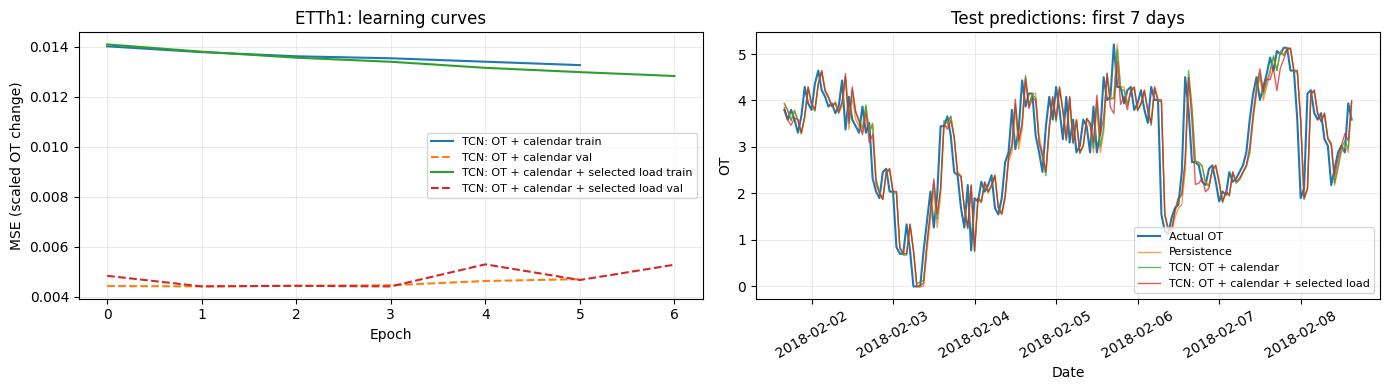

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all_modified/ETTh1 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTh1_tcn_optimized_outputs.zip

=== ETTh2: 間隔 0 days 01:00:00, 履歴 24ステップ ===
train: 12,170件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:00:00
validation: 1,742件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:00:00
test: 3,484件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:00:00
全15組の相関を調べ、OTとの相関を優先して負荷列を選択


,dataset,feature_1,feature_2,pearson_r,abs_r_over_0_9,abs_corr_with_OT_1,abs_corr_with_OT_2,selected_load_columns,dropped_load_columns
0,ETTh2,HUFL,HULL,0.7696,False,0.0177,0.1101,"HUFL,MUFL,MULL,LUFL,LULL",HULL
1,ETTh2,HUFL,MUFL,0.0294,False,0.0177,0.2158,"HUFL,MUFL,MULL,LUFL,LULL",HULL
2,ETTh2,HUFL,MULL,0.6726,False,0.0177,0.3111,"HUFL,MUFL,MULL,LUFL,LULL",HULL
3,ETTh2,HUFL,LUFL,0.6083,False,0.0177,0.3395,"HUFL,MUFL,MULL,LUFL,LULL",HULL
4,ETTh2,HUFL,LULL,0.1781,False,0.0177,0.1209,"HUFL,MUFL,MULL,LUFL,LULL",HULL
5,ETTh2,HULL,MUFL,0.0263,False,0.1101,0.2158,"HUFL,MUFL,MULL,LUFL,LULL",HULL
6,ETTh2,HULL,MULL,0.9029,True,0.1101,0.3111,"HUFL,MUFL,MULL,LUFL,LULL",HULL
7,ETTh2,HULL,LUFL,0.6045,False,0.1101,0.3395,"HUFL,MUFL,MULL,LUFL,LULL",HULL
8,ETTh2,HULL,LULL,0.2621,False,0.1101,0.1209,"HUFL,MUFL,MULL,LUFL,LULL",HULL
9,ETTh2,MUFL,MULL,0.2382,False,0.2158,0.3111,"HUFL,MUFL,MULL,LUFL,LULL",HULL


TCNに入力する負荷列: ['HUFL', 'MUFL', 'MULL', 'LUFL', 'LULL']

--- ETTh2: TCN: OT + calendar [base], patience=5, min_delta=1e-05 ---
Epoch 1/30
96/96 - 12s - 125ms/step - loss: 0.0074 - val_loss: 0.0041
Epoch 2/30
96/96 - 5s - 48ms/step - loss: 0.0061 - val_loss: 0.0047
Epoch 3/30
96/96 - 6s - 64ms/step - loss: 0.0057 - val_loss: 0.0032
Epoch 4/30
96/96 - 9s - 96ms/step - loss: 0.0053 - val_loss: 0.0034
Epoch 5/30
96/96 - 7s - 75ms/step - loss: 0.0051 - val_loss: 0.0025
Epoch 6/30
96/96 - 5s - 49ms/step - loss: 0.0050 - val_loss: 0.0025
Epoch 7/30
96/96 - 5s - 49ms/step - loss: 0.0048 - val_loss: 0.0027
Epoch 8/30
96/96 - 7s - 70ms/step - loss: 0.0047 - val_loss: 0.0023
Epoch 9/30
96/96 - 8s - 86ms/step - loss: 0.0047 - val_loss: 0.0024
Epoch 10/30
96/96 - 7s - 72ms/step - loss: 0.0045 - val_loss: 0.0026
Epoch 11/30
96/96 - 5s - 49ms/step - loss: 0.0044 - val_loss: 0.0025
Epoch 12/30
96/96 - 6s - 60ms/step - loss: 0.0044 - val_loss: 0.0024
Epoch 13/30
96/96 - 6s - 59ms/step - loss: 0.0044 - va

,dataset,stage,feature_set,preset,filters,dropout,learning_rate,correction_weight,validation_MAE,validation_RMSE,selected
6,ETTh2,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.379794,0.508590,True
5,ETTh2,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,0.75,0.435650,0.597390,False
4,ETTh2,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,0.50,0.531234,0.754351,False
1,ETTh2,learning_preset,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.379794,0.508590,True
2,ETTh2,learning_preset,TCN: OT + calendar,light,16,0.1,0.0010,1.00,0.390271,0.512184,False
0,ETTh2,learning_preset,TCN: OT + calendar,base,32,0.0,0.0010,1.00,0.403689,0.545178,False
3,ETTh2,learning_preset,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.00,0.426732,0.572465,False
13,ETTh2,inference_weight,TCN: OT + calendar + selected load,slow_lr,32,0.1,0.0005,1.00,0.453238,0.608189,True
12,ETTh2,inference_weight,TCN: OT + calendar + selected load,slow_lr,32,0.1,0.0005,0.75,0.480913,0.655699,False
11,ETTh2,inference_weight,TCN: OT + calendar + selected load,slow_lr,32,0.1,0.0005,0.50,0.552046,0.781571,False


選択された設定:


,feature_set,preset,filters,dropout,learning_rate,correction_weight
0,TCN: OT + calendar,reg,32,0.2,0.0010,1.0
1,TCN: OT + calendar + selected load,slow_lr,32,0.1,0.0005,1.0


,dataset,split,model,count,MAE,RMSE
0,ETTh2,validation,Persistence,1742,0.7803,1.1555
1,ETTh2,validation,TCN: OT + calendar,1742,0.3798,0.5086
2,ETTh2,validation,TCN: OT + calendar + selected load,1742,0.4532,0.6082
3,ETTh2,test,Persistence,3484,0.9716,1.3312
4,ETTh2,test,TCN: OT + calendar,3484,0.4718,0.6754
5,ETTh2,test,TCN: OT + calendar + selected load,3484,0.5313,0.7706


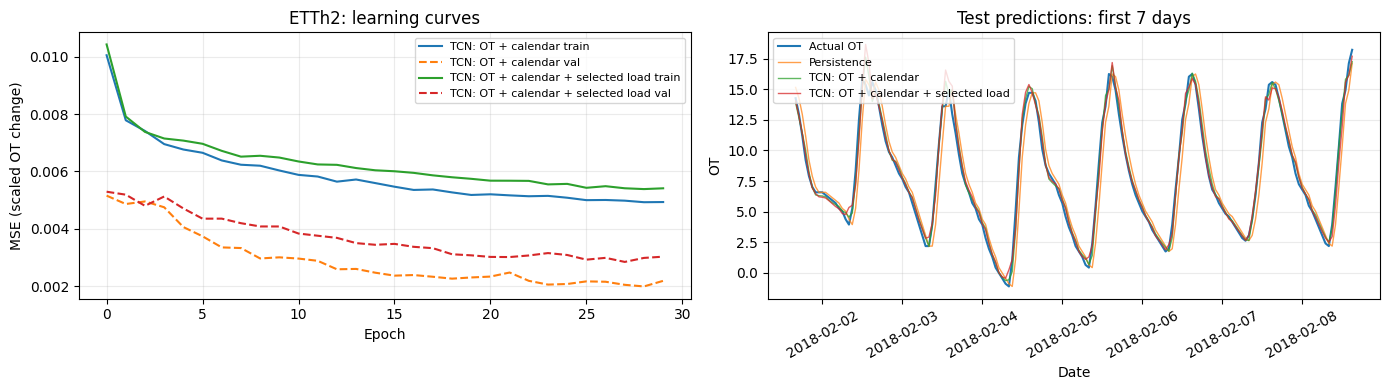

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all_modified/ETTh2 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTh2_tcn_optimized_outputs.zip

=== ETTm1: 間隔 0 days 00:15:00, 履歴 96ステップ ===
train: 48,680件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:45:00
validation: 6,968件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:45:00
test: 13,936件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:45:00
全15組の相関を調べ、OTとの相関を優先して負荷列を選択


,dataset,feature_1,feature_2,pearson_r,abs_r_over_0_9,abs_corr_with_OT_1,abs_corr_with_OT_2,selected_load_columns,dropped_load_columns
0,ETTm1,HUFL,HULL,0.1044,False,0.1572,0.4669,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
1,ETTm1,HUFL,MUFL,0.9845,True,0.1572,0.1086,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
2,ETTm1,HUFL,MULL,0.0289,False,0.1572,0.4217,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
3,ETTm1,HUFL,LUFL,0.2504,False,0.1572,0.3261,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
4,ETTm1,HUFL,LULL,0.0722,False,0.1572,0.1763,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
5,ETTm1,HULL,MUFL,0.0645,False,0.4669,0.1086,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
6,ETTm1,HULL,MULL,0.9239,True,0.4669,0.4217,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
7,ETTm1,HULL,LUFL,0.1968,False,0.4669,0.3261,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
8,ETTm1,HULL,LULL,0.3367,False,0.4669,0.1763,"HUFL,HULL,LUFL,LULL","MUFL,MULL"
9,ETTm1,MUFL,MULL,0.0178,False,0.1086,0.4217,"HUFL,HULL,LUFL,LULL","MUFL,MULL"


TCNに入力する負荷列: ['HUFL', 'HULL', 'LUFL', 'LULL']

--- ETTm1: TCN: OT + calendar [base], patience=3, min_delta=1e-05 ---
Epoch 1/30
381/381 - 58s - 153ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 2/30
381/381 - 52s - 138ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 3/30
381/381 - 83s - 218ms/step - loss: 0.0034 - val_loss: 0.0013
Epoch 4/30
381/381 - 53s - 139ms/step - loss: 0.0034 - val_loss: 0.0013

--- ETTm1: TCN: OT + calendar [reg], patience=3, min_delta=1e-05 ---
Epoch 1/30
381/381 - 67s - 176ms/step - loss: 0.0035 - val_loss: 0.0012
Epoch 2/30
381/381 - 80s - 211ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 3/30
381/381 - 82s - 216ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 4/30
381/381 - 60s - 157ms/step - loss: 0.0034 - val_loss: 0.0012

--- ETTm1: TCN: OT + calendar [light], patience=3, min_delta=1e-05 ---
Epoch 1/30
381/381 - 46s - 120ms/step - loss: 0.0035 - val_loss: 0.0012
Epoch 2/30
381/381 - 42s - 109ms/step - loss: 0.0034 - val_loss: 0.0012
Epoch 3/30
381/381 - 

,dataset,stage,feature_set,preset,filters,dropout,learning_rate,correction_weight,validation_MAE,validation_RMSE,selected
4,ETTm1,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,0.50,0.207883,0.291693,True
5,ETTm1,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,0.75,0.208188,0.291662,False
6,ETTm1,inference_weight,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.208492,0.291653,False
1,ETTm1,learning_preset,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.208492,0.291653,True
2,ETTm1,learning_preset,TCN: OT + calendar,light,16,0.1,0.0010,1.00,0.209843,0.291202,False
3,ETTm1,learning_preset,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.00,0.209937,0.291702,False
0,ETTm1,learning_preset,TCN: OT + calendar,base,32,0.0,0.0010,1.00,0.211496,0.292234,False
11,ETTm1,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,0.50,0.207577,0.290970,True
12,ETTm1,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,0.75,0.207736,0.290725,False
13,ETTm1,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,1.00,0.207938,0.290602,False


選択された設定:


,feature_set,preset,filters,dropout,learning_rate,correction_weight
0,TCN: OT + calendar,reg,32,0.2,0.001,0.5
1,TCN: OT + calendar + selected load,reg,32,0.2,0.001,0.5


,dataset,split,model,count,MAE,RMSE
0,ETTm1,validation,Persistence,6968,0.2073,0.2918
1,ETTm1,validation,TCN: OT + calendar,6968,0.2079,0.2917
2,ETTm1,validation,TCN: OT + calendar + selected load,6968,0.2076,0.2910
3,ETTm1,test,Persistence,13936,0.2141,0.3225
4,ETTm1,test,TCN: OT + calendar,13936,0.2144,0.3223
5,ETTm1,test,TCN: OT + calendar + selected load,13936,0.2136,0.3208


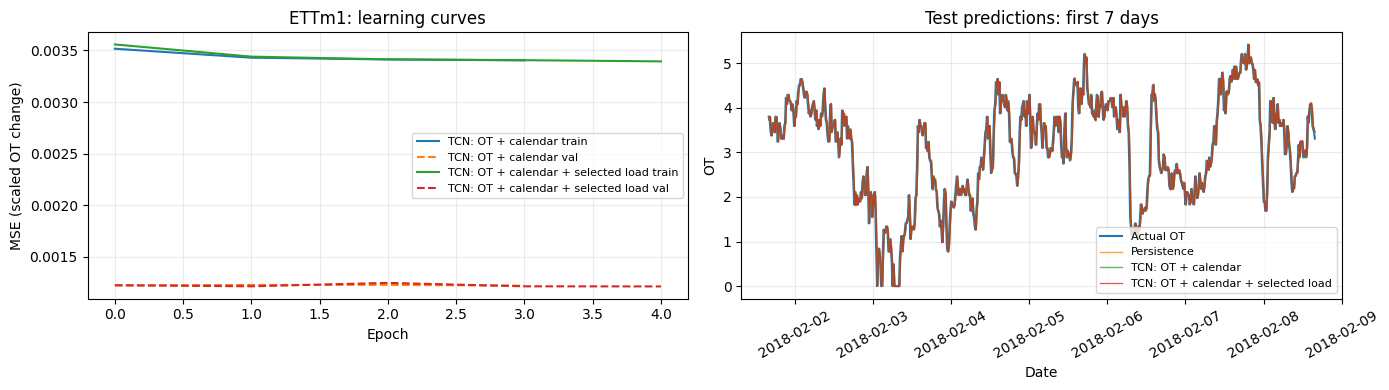

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all_modified/ETTm1 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTm1_tcn_optimized_outputs.zip

=== ETTm2: 間隔 0 days 00:15:00, 履歴 96ステップ ===
train: 48,680件, 予測対象 2016-07-02 00:00:00 〜 2017-11-21 01:45:00
validation: 6,968件, 予測対象 2017-11-21 02:00:00 〜 2018-02-01 15:45:00
test: 13,936件, 予測対象 2018-02-01 16:00:00 〜 2018-06-26 19:45:00
全15組の相関を調べ、OTとの相関を優先して負荷列を選択


,dataset,feature_1,feature_2,pearson_r,abs_r_over_0_9,abs_corr_with_OT_1,abs_corr_with_OT_2,selected_load_columns,dropped_load_columns
0,ETTm2,HUFL,HULL,0.7697,False,0.0169,0.1089,"HUFL,MUFL,MULL,LUFL,LULL",HULL
1,ETTm2,HUFL,MUFL,0.0290,False,0.0169,0.2162,"HUFL,MUFL,MULL,LUFL,LULL",HULL
2,ETTm2,HUFL,MULL,0.6725,False,0.0169,0.3112,"HUFL,MUFL,MULL,LUFL,LULL",HULL
3,ETTm2,HUFL,LUFL,0.6094,False,0.0169,0.3403,"HUFL,MUFL,MULL,LUFL,LULL",HULL
4,ETTm2,HUFL,LULL,0.1785,False,0.0169,0.1216,"HUFL,MUFL,MULL,LUFL,LULL",HULL
5,ETTm2,HULL,MUFL,0.0249,False,0.1089,0.2162,"HUFL,MUFL,MULL,LUFL,LULL",HULL
6,ETTm2,HULL,MULL,0.9022,True,0.1089,0.3112,"HUFL,MUFL,MULL,LUFL,LULL",HULL
7,ETTm2,HULL,LUFL,0.6044,False,0.1089,0.3403,"HUFL,MUFL,MULL,LUFL,LULL",HULL
8,ETTm2,HULL,LULL,0.2648,False,0.1089,0.1216,"HUFL,MUFL,MULL,LUFL,LULL",HULL
9,ETTm2,MUFL,MULL,0.2376,False,0.2162,0.3112,"HUFL,MUFL,MULL,LUFL,LULL",HULL


TCNに入力する負荷列: ['HUFL', 'MUFL', 'MULL', 'LUFL', 'LULL']

--- ETTm2: TCN: OT + calendar [base], patience=3, min_delta=1e-05 ---
Epoch 1/30
381/381 - 61s - 159ms/step - loss: 0.0010 - val_loss: 3.1364e-04
Epoch 2/30
381/381 - 80s - 209ms/step - loss: 9.2074e-04 - val_loss: 3.0655e-04
Epoch 3/30
381/381 - 54s - 141ms/step - loss: 8.9300e-04 - val_loss: 2.9860e-04
Epoch 4/30
381/381 - 83s - 218ms/step - loss: 8.7394e-04 - val_loss: 2.7671e-04
Epoch 5/30
381/381 - 82s - 214ms/step - loss: 8.6421e-04 - val_loss: 2.7026e-04
Epoch 6/30
381/381 - 56s - 146ms/step - loss: 8.5814e-04 - val_loss: 2.7597e-04
Epoch 7/30
381/381 - 53s - 138ms/step - loss: 8.3656e-04 - val_loss: 3.5638e-04

--- ETTm2: TCN: OT + calendar [reg], patience=3, min_delta=1e-05 ---
Epoch 1/30
381/381 - 68s - 177ms/step - loss: 0.0012 - val_loss: 4.3906e-04
Epoch 2/30
381/381 - 81s - 213ms/step - loss: 0.0010 - val_loss: 4.0101e-04
Epoch 3/30
381/381 - 62s - 163ms/step - loss: 9.9429e-04 - val_loss: 3.6808e-04
Epoch 4/30
381/38

,dataset,stage,feature_set,preset,filters,dropout,learning_rate,correction_weight,validation_MAE,validation_RMSE,selected
6,ETTm2,inference_weight,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.00,0.141473,0.183035,True
5,ETTm2,inference_weight,TCN: OT + calendar,slow_lr,32,0.1,0.0005,0.75,0.144724,0.193831,False
4,ETTm2,inference_weight,TCN: OT + calendar,slow_lr,32,0.1,0.0005,0.50,0.158361,0.224166,False
3,ETTm2,learning_preset,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.00,0.141473,0.183035,True
1,ETTm2,learning_preset,TCN: OT + calendar,reg,32,0.2,0.0010,1.00,0.141550,0.180207,False
0,ETTm2,learning_preset,TCN: OT + calendar,base,32,0.0,0.0010,1.00,0.146545,0.189643,False
2,ETTm2,learning_preset,TCN: OT + calendar,light,16,0.1,0.0010,1.00,0.156199,0.199057,False
13,ETTm2,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,1.00,0.141441,0.182833,True
12,ETTm2,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,0.75,0.150169,0.202302,False
11,ETTm2,inference_weight,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,0.50,0.163971,0.234012,False


選択された設定:


,feature_set,preset,filters,dropout,learning_rate,correction_weight
0,TCN: OT + calendar,slow_lr,32,0.1,0.0005,1.0
1,TCN: OT + calendar + selected load,reg,32,0.2,0.0010,1.0


,dataset,split,model,count,MAE,RMSE
0,ETTm2,validation,Persistence,6968,0.1970,0.3185
1,ETTm2,validation,TCN: OT + calendar,6968,0.1415,0.1830
2,ETTm2,validation,TCN: OT + calendar + selected load,6968,0.1414,0.1828
3,ETTm2,test,Persistence,13936,0.2467,0.3692
4,ETTm2,test,TCN: OT + calendar,13936,0.1629,0.2255
5,ETTm2,test,TCN: OT + calendar + selected load,13936,0.1654,0.2284


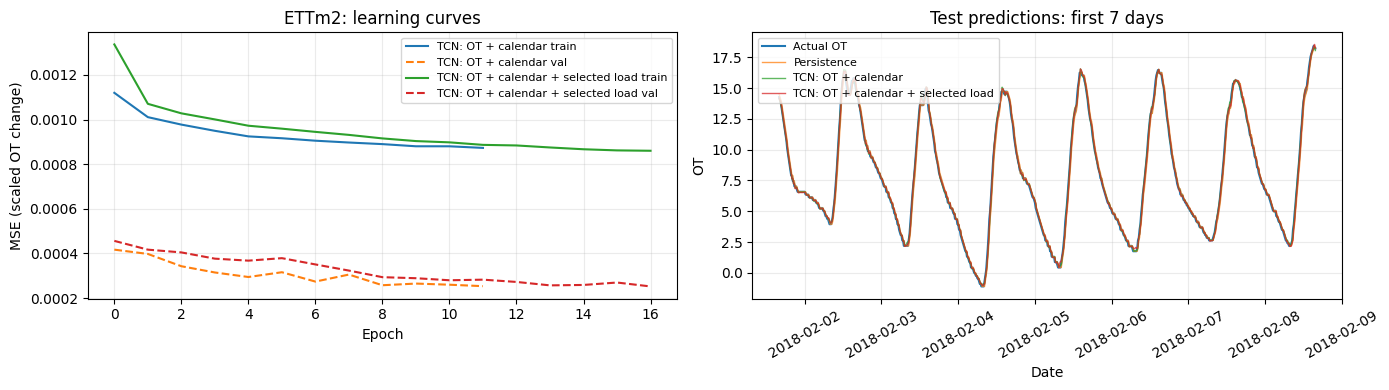

保存先: /content/drive/Othercomputers/マイ Mac/assignment-main/model_output_tcn_all_modified/ETTm2 ZIP: /content/drive/Othercomputers/マイ Mac/assignment-main/ETTm2_tcn_optimized_outputs.zip
全系列の評価


,dataset,split,model,count,MAE,RMSE
0,ETTh1,validation,Persistence,1742,0.4034,0.5653
1,ETTh1,validation,TCN: OT + calendar,1742,0.3988,0.5557
2,ETTh1,validation,TCN: OT + calendar + selected load,1742,0.3943,0.5535
3,ETTh1,test,Persistence,3484,0.4481,0.6542
4,ETTh1,test,TCN: OT + calendar,3484,0.4312,0.6350
5,ETTh1,test,TCN: OT + calendar + selected load,3484,0.4212,0.6233
6,ETTh2,validation,Persistence,1742,0.7803,1.1555
7,ETTh2,validation,TCN: OT + calendar,1742,0.3798,0.5086
8,ETTh2,validation,TCN: OT + calendar + selected load,1742,0.4532,0.6082
9,ETTh2,test,Persistence,3484,0.9716,1.3312


In [ ]:
from tcn import TCN
from itertools import combinations
import shutil

DATASETS = ["ETTh1", "ETTh2", "ETTm1", "ETTm2"]
OUTPUT_ROOT = DATA_DIR.parent / "model_output_tcn_all_modified"
CALENDAR_PATTERN_WEIGHT = 1.0
PATTERN_PRIOR_COUNT = 20
CORRELATION_THRESHOLD = 0.9
TCN_DILATIONS = [1, 2, 4, 8, 16, 32]
CORRECTION_WEIGHT_CANDIDATES = [0.5, 0.75, 1.0]
PARAM_CANDIDATES = [
    {"name": "base", "filters": 32, "dropout": 0.0, "lr": 1e-3},
    {"name": "reg", "filters": 32, "dropout": 0.2, "lr": 1e-3},
    {"name": "light", "filters": 16, "dropout": 0.1, "lr": 1e-3},
    {"name": "slow_lr", "filters": 32, "dropout": 0.1, "lr": 5e-4},
]
EARLY_STOPPING_MIN_DELTA = 1e-5


def run_dataset(dataset_name):
    data_path = DATA_DIR / f"{dataset_name}.csv"
    if not data_path.is_file():
        raise FileNotFoundError(f"CSVが見つかりません: {data_path}")

    load_columns = ["HUFL", "HULL", "LUFL", "MULL", "LUFL", "LULL"]
    load_columns = list(dict.fromkeys(["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL"]))
    sensor_columns = ["OT"] + load_columns
    frame = pd.read_csv(data_path, parse_dates=["date"])
    missing_columns = set(["date"] + sensor_columns) - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{dataset_name}: 必要な列がありません: {missing_columns}")
    if frame[["date"] + sensor_columns].isna().any().any():
        raise ValueError(f"{dataset_name}: 日時またはセンサ値に欠損があります。")
    if not np.isfinite(frame[sensor_columns].to_numpy(dtype=float)).all():
        raise ValueError(f"{dataset_name}: センサ値に無限大があります。")

    interval = pd.Timedelta(hours=1) if dataset_name.startswith("ETTh") else pd.Timedelta(minutes=15)
    if not frame["date"].diff().iloc[1:].eq(interval).all():
        raise ValueError(f"{dataset_name}: 日時が重複、不整列、または{interval}間隔でない箇所があります。")

    lookback = int(pd.Timedelta(days=1) / interval)
    train_end = int(len(frame) * 0.7)
    validation_end = int(len(frame) * 0.8)
    if train_end <= lookback or validation_end <= train_end or validation_end >= len(frame):
        raise ValueError(f"{dataset_name}: 指定した履歴長と分割に対してデータが不足しています。")

    timestamps = frame["date"]
    ot_values = frame["OT"].to_numpy(dtype=np.float32)
    train_indices = np.arange(lookback, train_end, dtype=np.int32)
    validation_indices = np.arange(train_end, validation_end, dtype=np.int32)
    test_indices = np.arange(validation_end, len(frame), dtype=np.int32)
    print(f"\n=== {dataset_name}: 間隔 {interval}, 履歴 {lookback}ステップ ===")
    for label, indices in [("train", train_indices), ("validation", validation_indices), ("test", test_indices)]:
        print(f"{label}: {len(indices):,}件, 予測対象 {timestamps.iloc[indices[0]]} 〜 {timestamps.iloc[indices[-1]]}")

    train_frame = frame.iloc[:train_end]
    load_correlation = train_frame[load_columns].corr(method="pearson")
    ot_load_correlation = train_frame[["OT"] + load_columns].corr(method="pearson").loc["OT", load_columns]
    pair_rows = []
    for first, second in combinations(load_columns, 2):
        pair_correlation = float(load_correlation.loc[first, second])
        pair_rows.append({
            "dataset": dataset_name,
            "feature_1": first,
            "feature_2": second,
            "pearson_r": pair_correlation,
            "abs_r_over_0_9": abs(pair_correlation) > CORRELATION_THRESHOLD,
            "abs_corr_with_OT_1": abs(float(ot_load_correlation[first])),
            "abs_corr_with_OT_2": abs(float(ot_load_correlation[second])),
        })
    load_pair_comparison = pd.DataFrame(pair_rows)
    if len(load_pair_comparison) != 15:
        raise RuntimeError(f"{dataset_name}: 負荷ペアは15組のはずです。")

    selected_load_columns = []
    ranked_loads = sorted(load_columns, key=lambda col: abs(float(ot_load_correlation[col])), reverse=True)
    for column in ranked_loads:
        redundant_with_selected = any(
            abs(float(load_correlation.loc[column, selected])) > CORRELATION_THRESHOLD
            for selected in selected_load_columns
        )
        if not redundant_with_selected:
            selected_load_columns.append(column)
    selected_load_columns = [column for column in load_columns if column in selected_load_columns]
    dropped_load_columns = [column for column in load_columns if column not in selected_load_columns]
    load_pair_comparison["selected_load_columns"] = ",".join(selected_load_columns)
    load_pair_comparison["dropped_load_columns"] = ",".join(dropped_load_columns)
    print(f"全{len(load_pair_comparison)}組の相関を調べ、OTとの相関を優先して負荷列を選択")
    display(load_pair_comparison.round(4))
    print("TCNに入力する負荷列:", selected_load_columns)

    scaler_columns = ["OT"] + selected_load_columns
    scaler = StandardScaler()
    scaler.fit(train_frame[scaler_columns])
    scaled_sensors = scaler.transform(frame[scaler_columns]).astype(np.float32)
    ot_scale = float(scaler.scale_[0])
    residuals = np.zeros(len(frame), dtype=np.float32)
    residuals[1:] = (ot_values[1:] - ot_values[:-1]) / ot_scale

    day_fraction = (timestamps.dt.hour * 60 + timestamps.dt.minute) / (24 * 60)
    week_fraction = (timestamps.dt.dayofweek + day_fraction) / 7
    year_fraction = (timestamps.dt.dayofyear - 1 + day_fraction) / np.where(timestamps.dt.is_leap_year, 366, 365)
    calendar = np.column_stack([
        np.sin(2 * np.pi * day_fraction), np.cos(2 * np.pi * day_fraction),
        np.sin(2 * np.pi * week_fraction), np.cos(2 * np.pi * week_fraction),
        np.sin(2 * np.pi * year_fraction), np.cos(2 * np.pi * year_fraction),
    ]).astype(np.float32)
    time_slots = (day_fraction * lookback).astype(int)
    training_changes = pd.DataFrame({
        "month": timestamps.iloc[train_indices].dt.month.to_numpy(),
        "time_slot": time_slots.iloc[train_indices].to_numpy(),
        "change": residuals[train_indices],
    })
    overall_change = float(training_changes["change"].mean())

    def calculate_pattern(group_column):
        grouped = training_changes.groupby(group_column)["change"].agg(["mean", "count"])
        grouped["pattern"] = (
            grouped["mean"] * grouped["count"] + overall_change * PATTERN_PRIOR_COUNT
        ) / (grouped["count"] + PATTERN_PRIOR_COUNT)
        return grouped

    seasonal_pattern = calculate_pattern("month")
    time_pattern = calculate_pattern("time_slot")
    seasonal_values = timestamps.dt.month.map(seasonal_pattern["pattern"]).fillna(overall_change).to_numpy()
    time_values = time_slots.map(time_pattern["pattern"]).fillna(overall_change).to_numpy(dtype=np.float32)
    next_patterns = np.zeros((len(frame), 2), dtype=np.float32)
    next_patterns[:-1, 0] = seasonal_values[1:]
    next_patterns[:-1, 1] = time_values[1:]
    next_patterns *= CALENDAR_PATTERN_WEIGHT
    feature_sets = {
        "TCN: OT + calendar": np.column_stack([scaled_sensors[:, 0], calendar, next_patterns]).astype(np.float32),
        "TCN: OT + calendar + selected load": np.column_stack([scaled_sensors, calendar, next_patterns]).astype(np.float32),
    }

    def make_dataset(feature_array, indices, training=False):
        feature_tensor = tf.constant(feature_array, dtype=tf.float32)
        target_tensor = tf.constant(residuals, dtype=tf.float32)
        offsets = tf.range(-lookback, 0, dtype=tf.int32)
        dataset = tf.data.Dataset.from_tensor_slices(indices)
        if training:
            dataset = dataset.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
        dataset = dataset.map(
            lambda index: (tf.gather(feature_tensor, index + offsets), tf.gather(target_tensor, index)),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    validation_actual = ot_values[validation_indices]
    validation_baseline = ot_values[validation_indices - 1]
    parameter_results = []
    selected_models = {}
    selected_histories = {}
    selected_settings = {}
    for name, feature_array in feature_sets.items():
        preset_trials = []
        for params in PARAM_CANDIDATES:
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(SEED)
            model = tf.keras.Sequential([
                tf.keras.layers.Input(shape=(lookback, feature_array.shape[1])),
                TCN(
                    nb_filters=params["filters"],
                    kernel_size=2,
                    dilations=TCN_DILATIONS,
                    dropout_rate=params["dropout"],
                    padding="causal",
                    return_sequences=False,
                ),
                tf.keras.layers.Dense(16, activation="relu"),
                tf.keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
            ])
            model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=params["lr"]), loss="mse")
            patience = 3 if dataset_name.startswith("ETTm") else 5
            early_stopping = tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=patience,
                min_delta=EARLY_STOPPING_MIN_DELTA, restore_best_weights=True,
            )
            trial_name = f"{name} [{params['name']}]"
            print(f"\n--- {dataset_name}: {trial_name}, patience={patience}, min_delta={EARLY_STOPPING_MIN_DELTA} ---")
            history = model.fit(
                make_dataset(feature_array, train_indices, training=True),
                validation_data=make_dataset(feature_array, validation_indices),
                epochs=EPOCHS, callbacks=[early_stopping], verbose=2,
            )
            validation_correction = model.predict(
                make_dataset(feature_array, validation_indices), verbose=0
            ).reshape(-1) * ot_scale
            preset_mae = mean_absolute_error(validation_actual, validation_baseline + validation_correction)
            preset_trials.append({
                "params": params, "model": model, "history": history.history,
                "validation_correction": validation_correction, "preset_validation_MAE": preset_mae,
            })

        best_trial = min(preset_trials, key=lambda trial: trial["preset_validation_MAE"])
        selected_models[name] = best_trial["model"]
        selected_histories[name] = best_trial["history"]
        best_preset = best_trial["params"]
        weight_trials = []
        for correction_weight in CORRECTION_WEIGHT_CANDIDATES:
            validation_prediction = validation_baseline + correction_weight * best_trial["validation_correction"]
            weight_trials.append({
                "correction_weight": correction_weight,
                "validation_MAE": mean_absolute_error(validation_actual, validation_prediction),
                "validation_RMSE": np.sqrt(mean_squared_error(validation_actual, validation_prediction)),
            })
        best_weight_trial = min(weight_trials, key=lambda trial: trial["validation_MAE"])
        selected_settings[name] = {
            "preset": best_preset["name"],
            "filters": best_preset["filters"],
            "dropout": best_preset["dropout"],
            "learning_rate": best_preset["lr"],
            "correction_weight": best_weight_trial["correction_weight"],
        }
        for trial in preset_trials:
            params = trial["params"]
            parameter_results.append({
                "dataset": dataset_name, "stage": "learning_preset", "feature_set": name,
                "preset": params["name"], "filters": params["filters"], "dropout": params["dropout"],
                "learning_rate": params["lr"], "correction_weight": 1.0,
                "validation_MAE": trial["preset_validation_MAE"],
                "validation_RMSE": np.sqrt(mean_squared_error(validation_actual, validation_baseline + trial["validation_correction"])),
                "selected": params["name"] == best_preset["name"],
            })
        for trial in weight_trials:
            parameter_results.append({
                "dataset": dataset_name, "stage": "inference_weight", "feature_set": name,
                "preset": best_preset["name"], "filters": best_preset["filters"],
                "dropout": best_preset["dropout"], "learning_rate": best_preset["lr"],
                "correction_weight": trial["correction_weight"],
                "validation_MAE": trial["validation_MAE"],
                "validation_RMSE": trial["validation_RMSE"],
                "selected": trial["correction_weight"] == best_weight_trial["correction_weight"],
            })

    parameter_comparison = pd.DataFrame(parameter_results)
    print("学習プリセットと推論補正係数の2段階検証")
    display(parameter_comparison.sort_values(["feature_set", "stage", "validation_MAE"]).round(6))
    print("選択された設定:")
    display(pd.DataFrame([{"feature_set": name, **settings} for name, settings in selected_settings.items()]))

    prediction_frames = []
    for split_name, indices in [("validation", validation_indices), ("test", test_indices)]:
        previous_ot = ot_values[indices - 1]
        predictions = {"Persistence": previous_ot}
        for name, feature_array in feature_sets.items():
            model = selected_models[name]
            correction = model.predict(make_dataset(feature_array, indices), verbose=0).reshape(-1) * ot_scale
            predictions[name] = previous_ot + selected_settings[name]["correction_weight"] * correction
        prediction_frames.append(pd.DataFrame({
            "split": split_name, "date": timestamps.iloc[indices].to_numpy(),
            "actual_OT": ot_values[indices], **predictions,
        }))

    all_predictions = pd.concat(prediction_frames, ignore_index=True)
    prediction_columns = ["Persistence", *feature_sets]
    results = []
    for split_name in ["validation", "test"]:
        split_frame = all_predictions[all_predictions["split"] == split_name]
        for model_name in prediction_columns:
            results.append({
                "dataset": dataset_name, "split": split_name, "model": model_name,
                "count": len(split_frame),
                "MAE": mean_absolute_error(split_frame["actual_OT"], split_frame[model_name]),
                "RMSE": np.sqrt(mean_squared_error(split_frame["actual_OT"], split_frame[model_name])),
            })
    metrics = pd.DataFrame(results)
    display(metrics.round(4))
    test_predictions = all_predictions[all_predictions["split"] == "test"].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for name, history in selected_histories.items():
        axes[0].plot(history["loss"], label=f"{name} train")
        axes[0].plot(history["val_loss"], linestyle="--", label=f"{name} val")
    axes[0].set(title=f"{dataset_name}: learning curves", xlabel="Epoch", ylabel="MSE (scaled OT change)")
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.25)
    plot_data = test_predictions.iloc[:min(len(test_predictions), lookback * 7)]
    axes[1].plot(plot_data["date"], plot_data["actual_OT"], label="Actual OT", linewidth=1.5)
    for model_name in prediction_columns:
        axes[1].plot(plot_data["date"], plot_data[model_name], label=model_name, alpha=0.75, linewidth=1)
    axes[1].set(title="Test predictions: first 7 days", xlabel="Date", ylabel="OT")
    axes[1].tick_params(axis="x", rotation=30)
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.25)
    fig.tight_layout()

    output_dir = OUTPUT_ROOT / dataset_name
    table_dir = output_dir / "tables"
    figure_dir = output_dir / "figures"
    table_dir.mkdir(parents=True, exist_ok=True)
    figure_dir.mkdir(parents=True, exist_ok=True)
    load_pair_comparison.to_csv(table_dir / f"{dataset_name}_all_load_pair_correlations.csv", index=False)
    load_correlation.to_csv(table_dir / f"{dataset_name}_load_correlation_matrix.csv")
    pd.DataFrame({"selected_load_columns": selected_load_columns}).to_csv(
        table_dir / f"{dataset_name}_selected_load_features.csv", index=False
    )
    parameter_comparison.to_csv(table_dir / f"{dataset_name}_parameter_validation.csv", index=False)
    metrics.to_csv(table_dir / f"{dataset_name}_metrics.csv", index=False)
    test_predictions.to_csv(table_dir / f"{dataset_name}_test_predictions.csv", index=False)
    fig.savefig(figure_dir / f"{dataset_name}_learning_curves_and_predictions.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    zip_path = shutil.make_archive(
        str(DATA_DIR.parent / f"{dataset_name}_tcn_optimized_outputs"), "zip", root_dir=output_dir
    )
    print("保存先:", output_dir, "ZIP:", zip_path)
    return metrics


missing_files = [str(DATA_DIR / f"{name}.csv") for name in DATASETS if not (DATA_DIR / f"{name}.csv").is_file()]
if missing_files:
    raise FileNotFoundError(f"対象CSVがありません: {missing_files}")
all_metrics = pd.concat([run_dataset(name) for name in DATASETS], ignore_index=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
all_metrics.to_csv(OUTPUT_ROOT / "all_datasets_metrics.csv", index=False)
print("全系列の評価")
display(all_metrics.round(4))